# 1. Load Car Plate Datasets

In [15]:
!pip install -U ultralytics roboflow

In [4]:
from roboflow import Roboflow
rf = Roboflow(api_key="wNPGxnIaS0ZRR6jYHRfn")
project = rf.workspace("zara-hara").project("car-plate-k6xij")
version = project.version(26)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...


In [16]:
print("Dataset location:", dataset.location)
print("Dataset object:", dataset)
DATASET_DIR = dataset.location

Dataset location: /content/car-plate-26
Dataset object: <roboflow.core.dataset.Dataset object at 0x7bd40add8c20>


In [17]:
from pathlib import Path
import shutil
import yaml

SOURCE_DIR = Path("/content/car-plate-26")
TARGET_DIR = Path("/content/car-plate-only")

# Create a separate dataset; preserve the original
for split in ["train", "valid", "test"]:
    src_images = SOURCE_DIR / split / "images"
    src_labels = SOURCE_DIR / split / "labels"

    dst_images = TARGET_DIR / split / "images"
    dst_labels = TARGET_DIR / split / "labels"

    dst_images.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    # Copy images and keep only the plate bounding boxes
    for image_path in src_images.iterdir():
        if image_path.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".webp"
        }:
            continue

        label_path = src_labels / f"{image_path.stem}.txt"

        if not label_path.exists():
            continue

        plate_lines = []

        for line in label_path.read_text().splitlines():
            values = line.split()

            if values and int(values[0]) == 50:
                plate_lines.append("0 " + " ".join(values[1:]))

        # Keep only images that contain at least one plate
        if plate_lines:
            shutil.copy2(
                image_path, dst_images / image_path.name
            )

            (dst_labels / f"{image_path.stem}.txt").write_text(
                "\n".join(plate_lines) + "\n"
            )

# Create a new one-class data.yaml
config = {
    "path": str(TARGET_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": ["plate"],
}

with open(TARGET_DIR / "data.yaml", "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("New dataset:", TARGET_DIR)
print("Classes:", config["names"])

New dataset: /content/car-plate-only
Classes: ['plate']


# 2. Build YOLO26 Model And Train It.

In [18]:
import ultralytics
from ultralytics import YOLO
print(ultralytics.checks())

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 47.4/112.6 GB disk)
None


In [19]:
model = YOLO("yolo26s.pt")

results = model.train(
    data="/content/car-plate-only/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    patience=10,
    project="runs/license_plate",
    name="yolo26m_plate_only"
)

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/car-plate-only/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26m_plate_only, nbs=64, nms=None, opset=None, optimi

Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno 9] Bad file descriptor


val: Scanning /content/car-plate-only/valid/labels... 2297 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2297/2297 1.3Kit/s 1.7s
val: New cache created: /content/car-plate-only/valid/labels.cache
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and determining best 'optimizer' and 'lr0' automatically... 
optimizer: AdamW(lr=0.002, momentum=0.9) with parameter groups 114 weight(decay=0.0), 126 weight(decay=0.0005), 126 bias(decay=0.0)
Plotting labels to /content/runs/detect/runs/license_plate/yolo26m_plate_only/labels.jpg... 
Using 9817 train, 2297 val images for fraction=1.0 at imgsz=640
Using 2 dataloader workers
Logging results to /content/runs/detect/runs/license_plate/yolo26m_plate_only
Starting training for 30 epochs...

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       1/30      9.64G      1.052      1.247   0.003825         20        640: 100% ━━━━━━━━━━━━ 614/614 2.7it/s 3:50
                 Class     Images  Instances      Box(P 

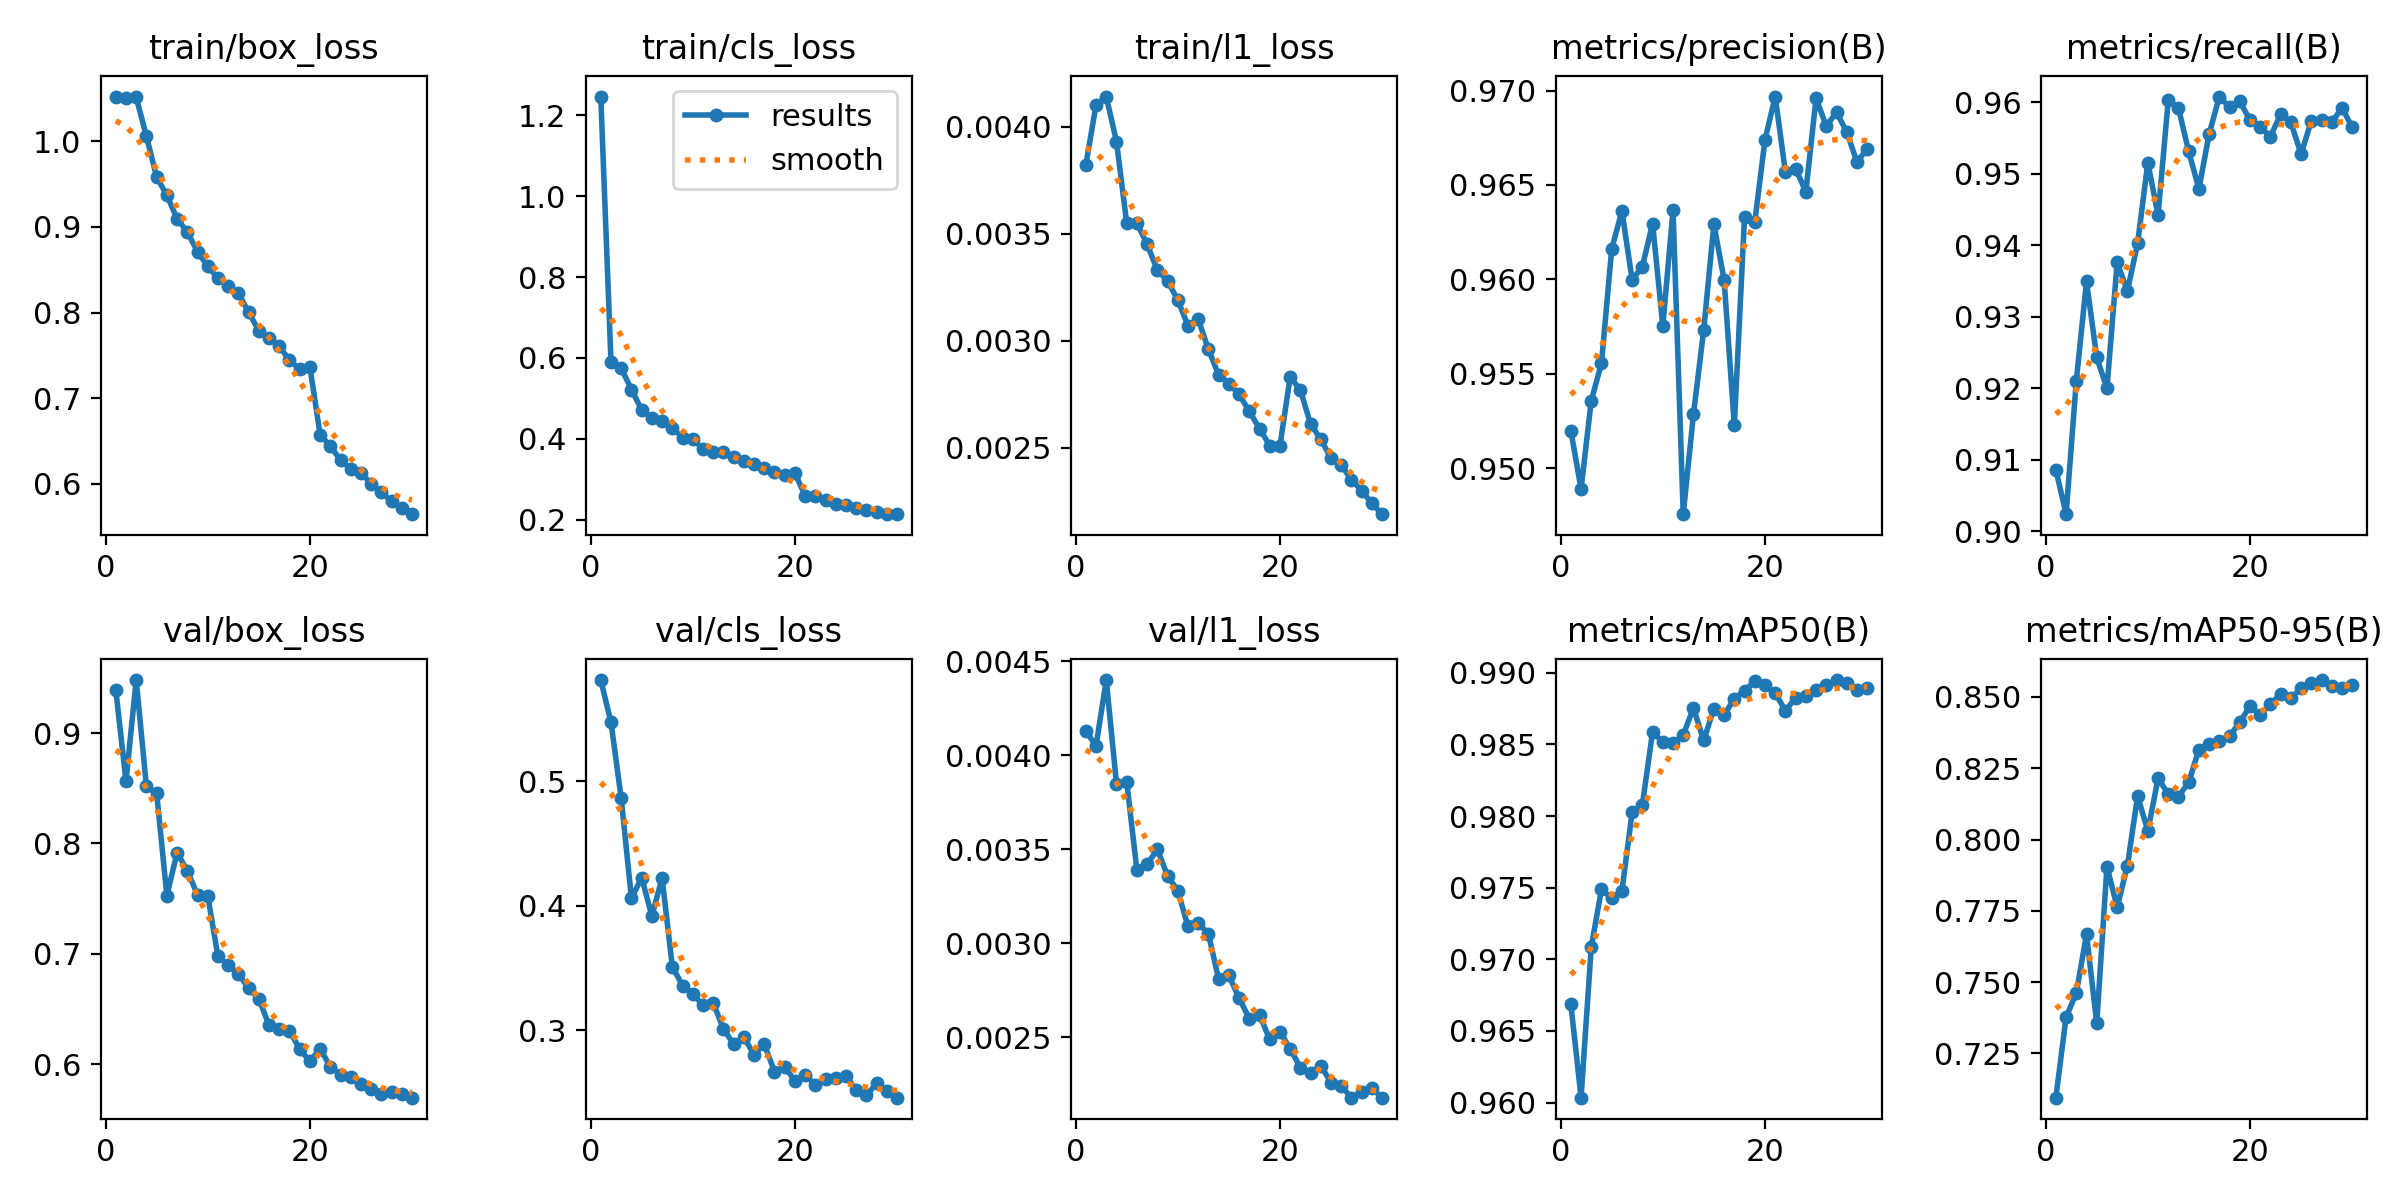

In [20]:
from IPython.display import display, Image
from pathlib import Path

# Get the training results directory
results_dir = Path(results.save_dir)

# Display the main results plot
plot_path = results_dir / "results.png"

if plot_path.exists():
    display(Image(filename=str(plot_path)))
else:
    print("results.png not found:", results_dir)

BoxF1_curve.png


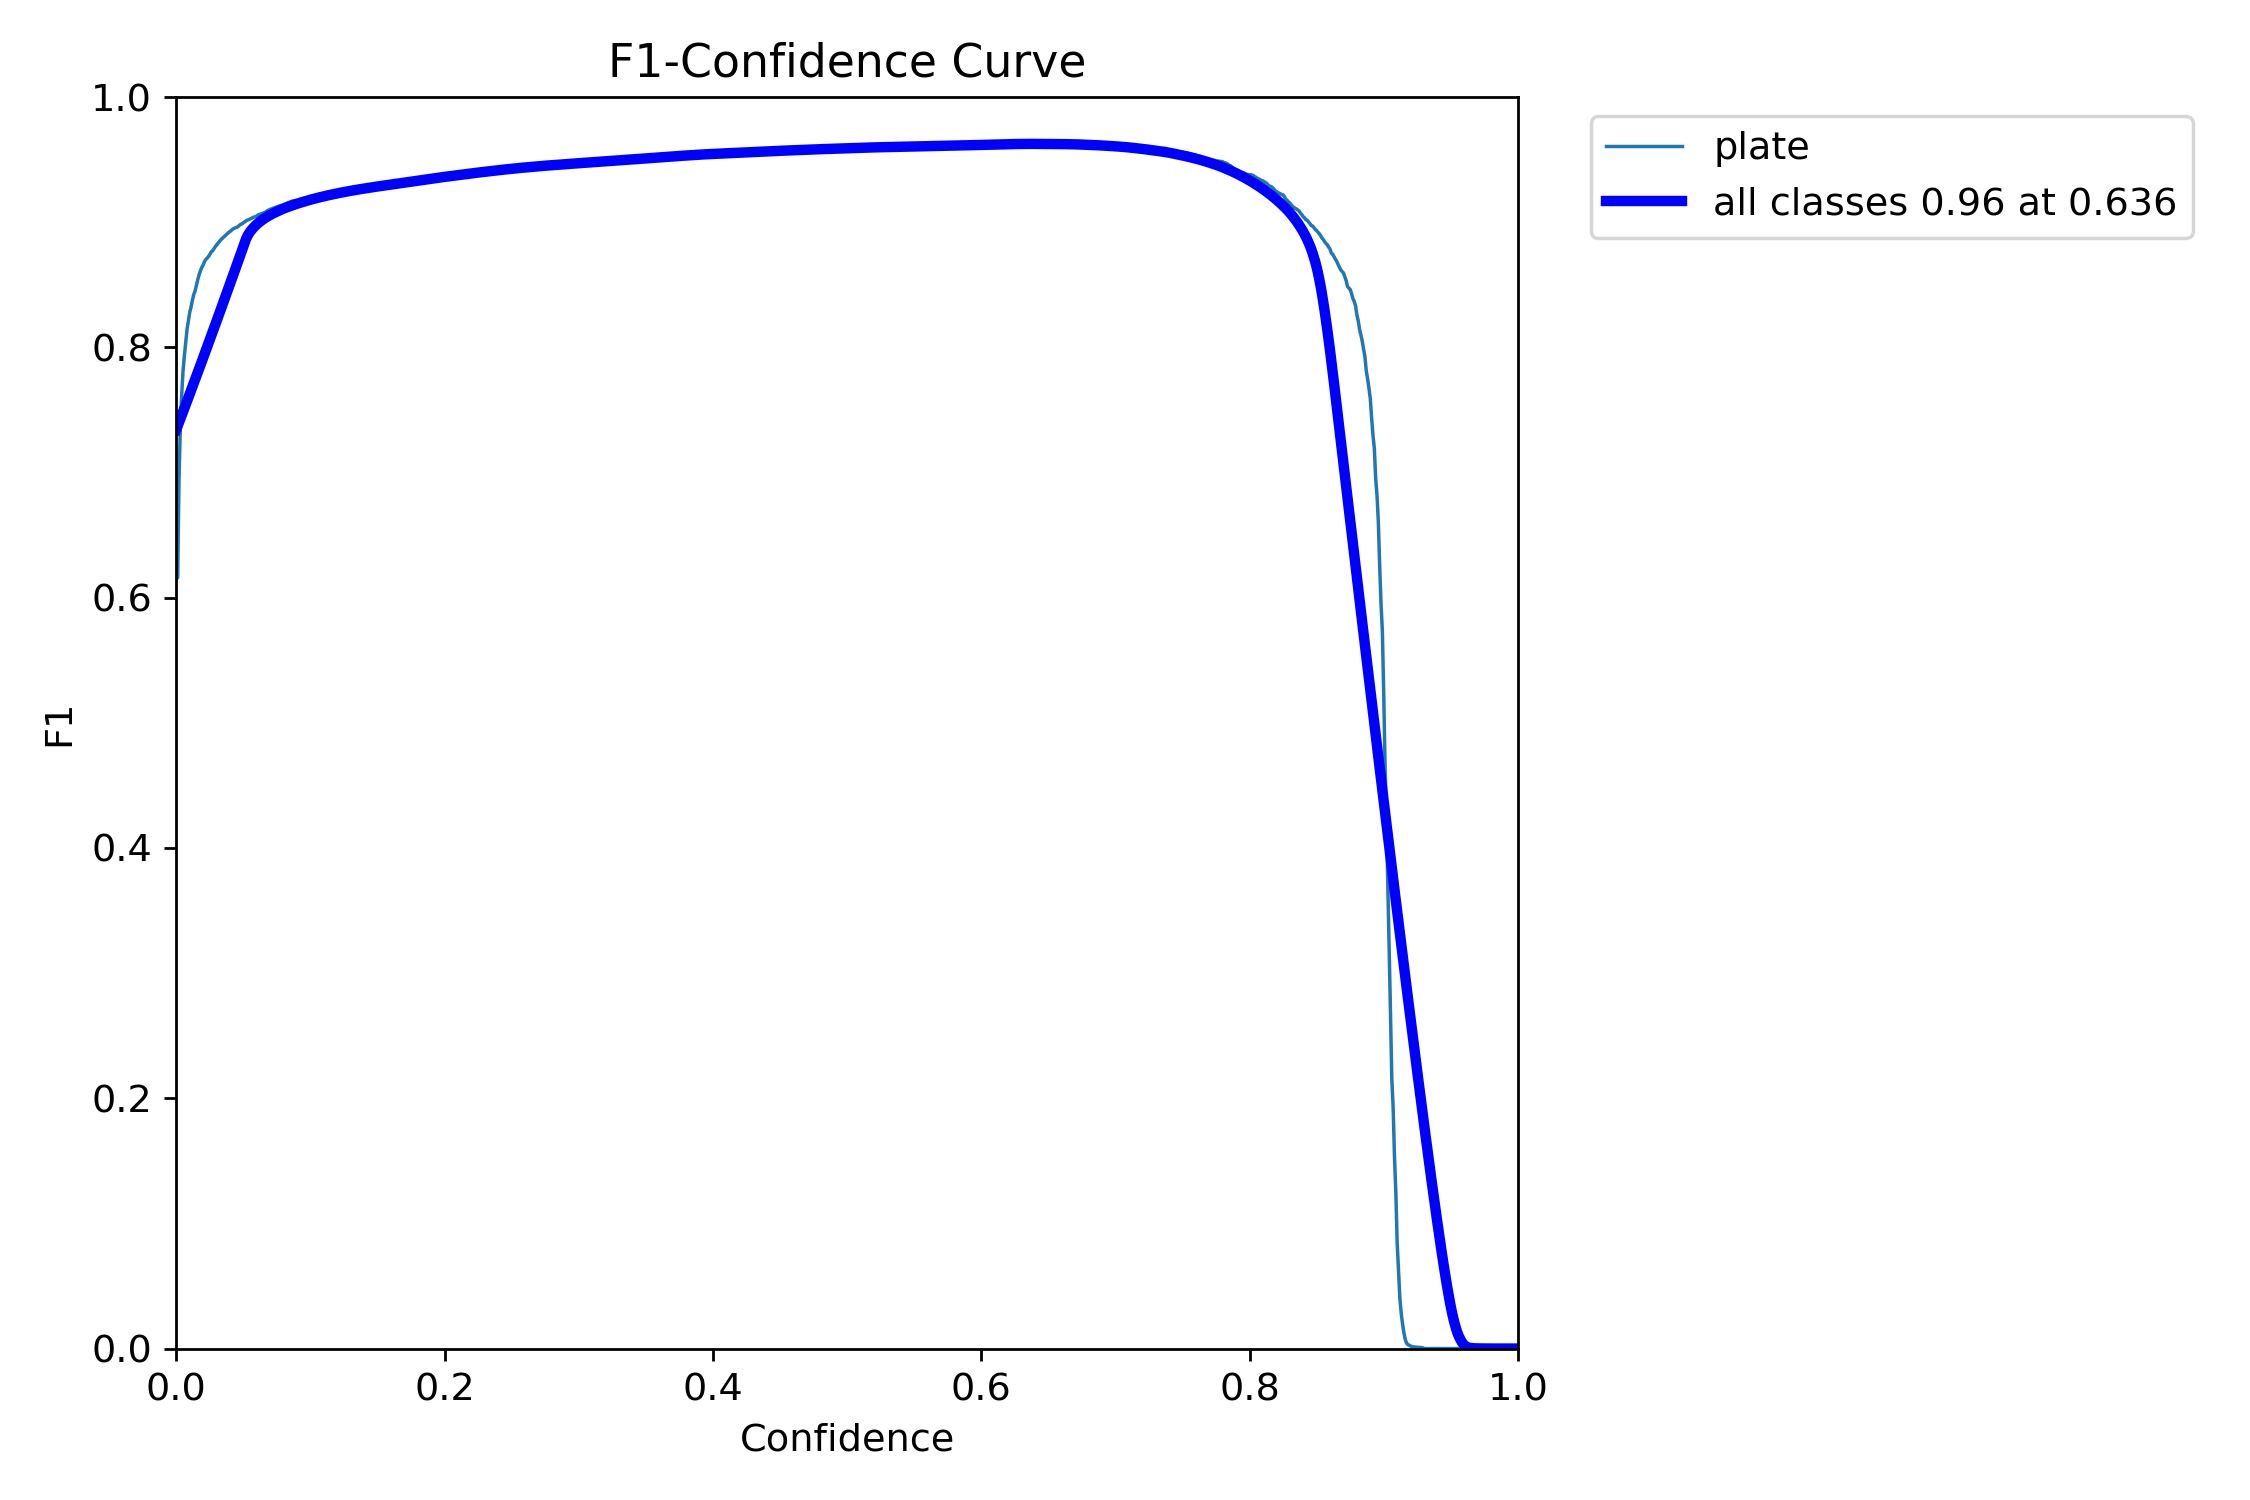

BoxPR_curve.png


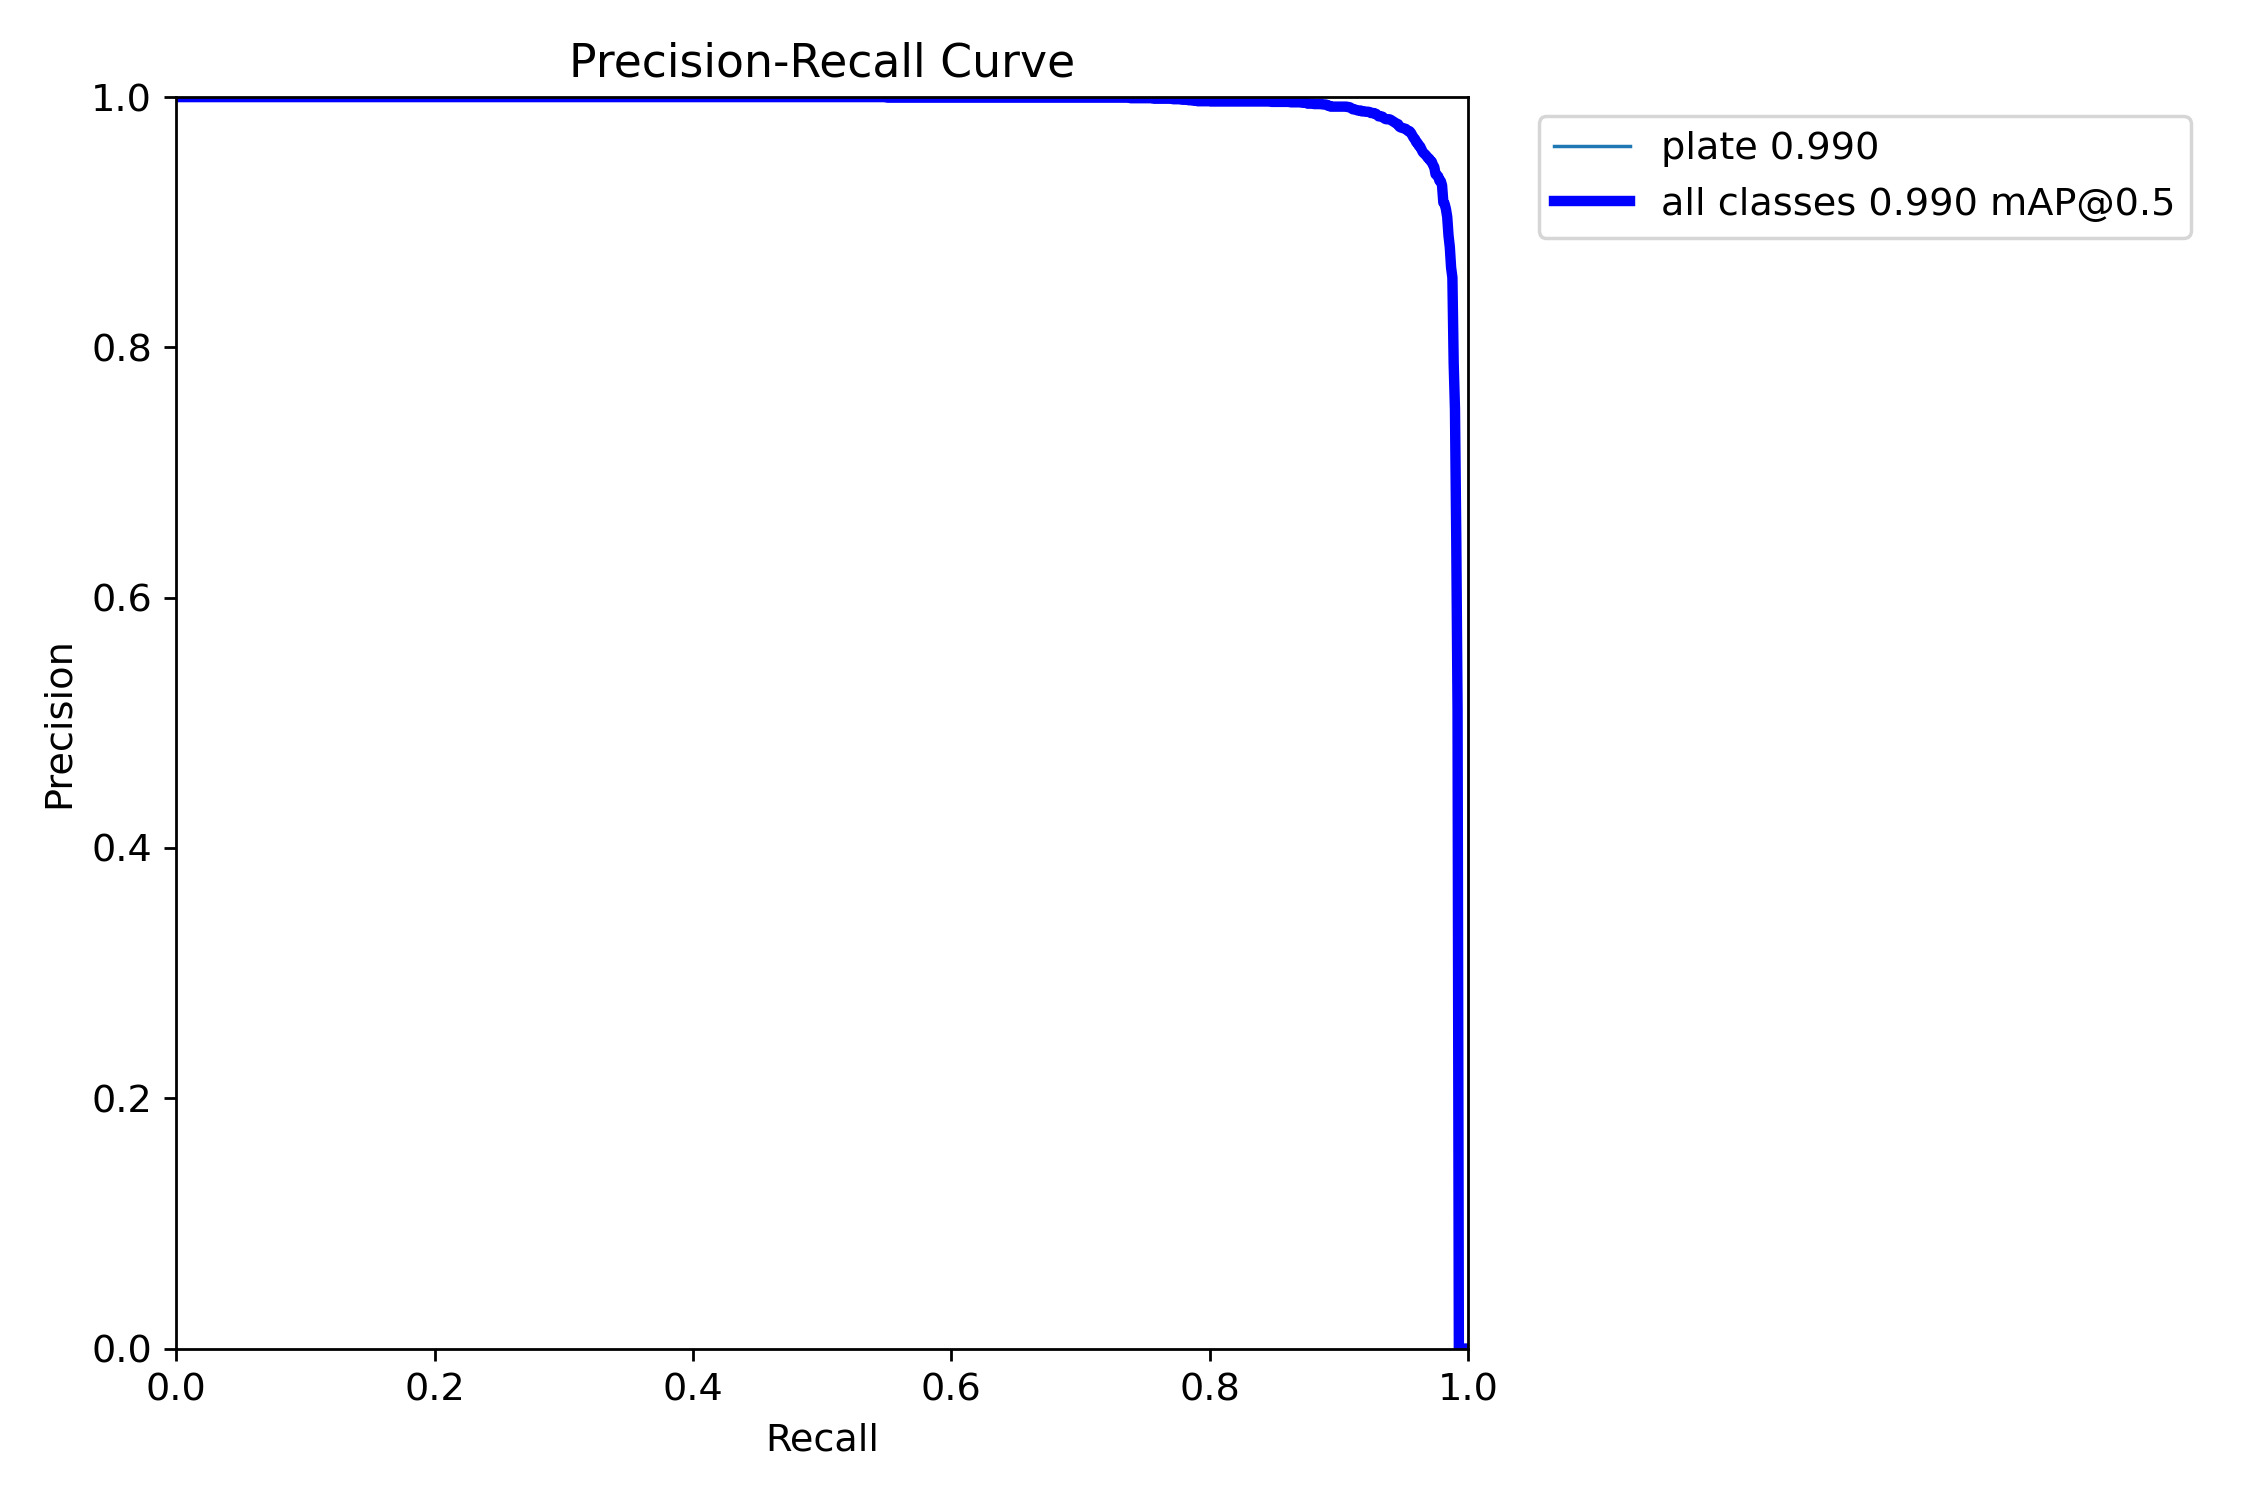

BoxP_curve.png


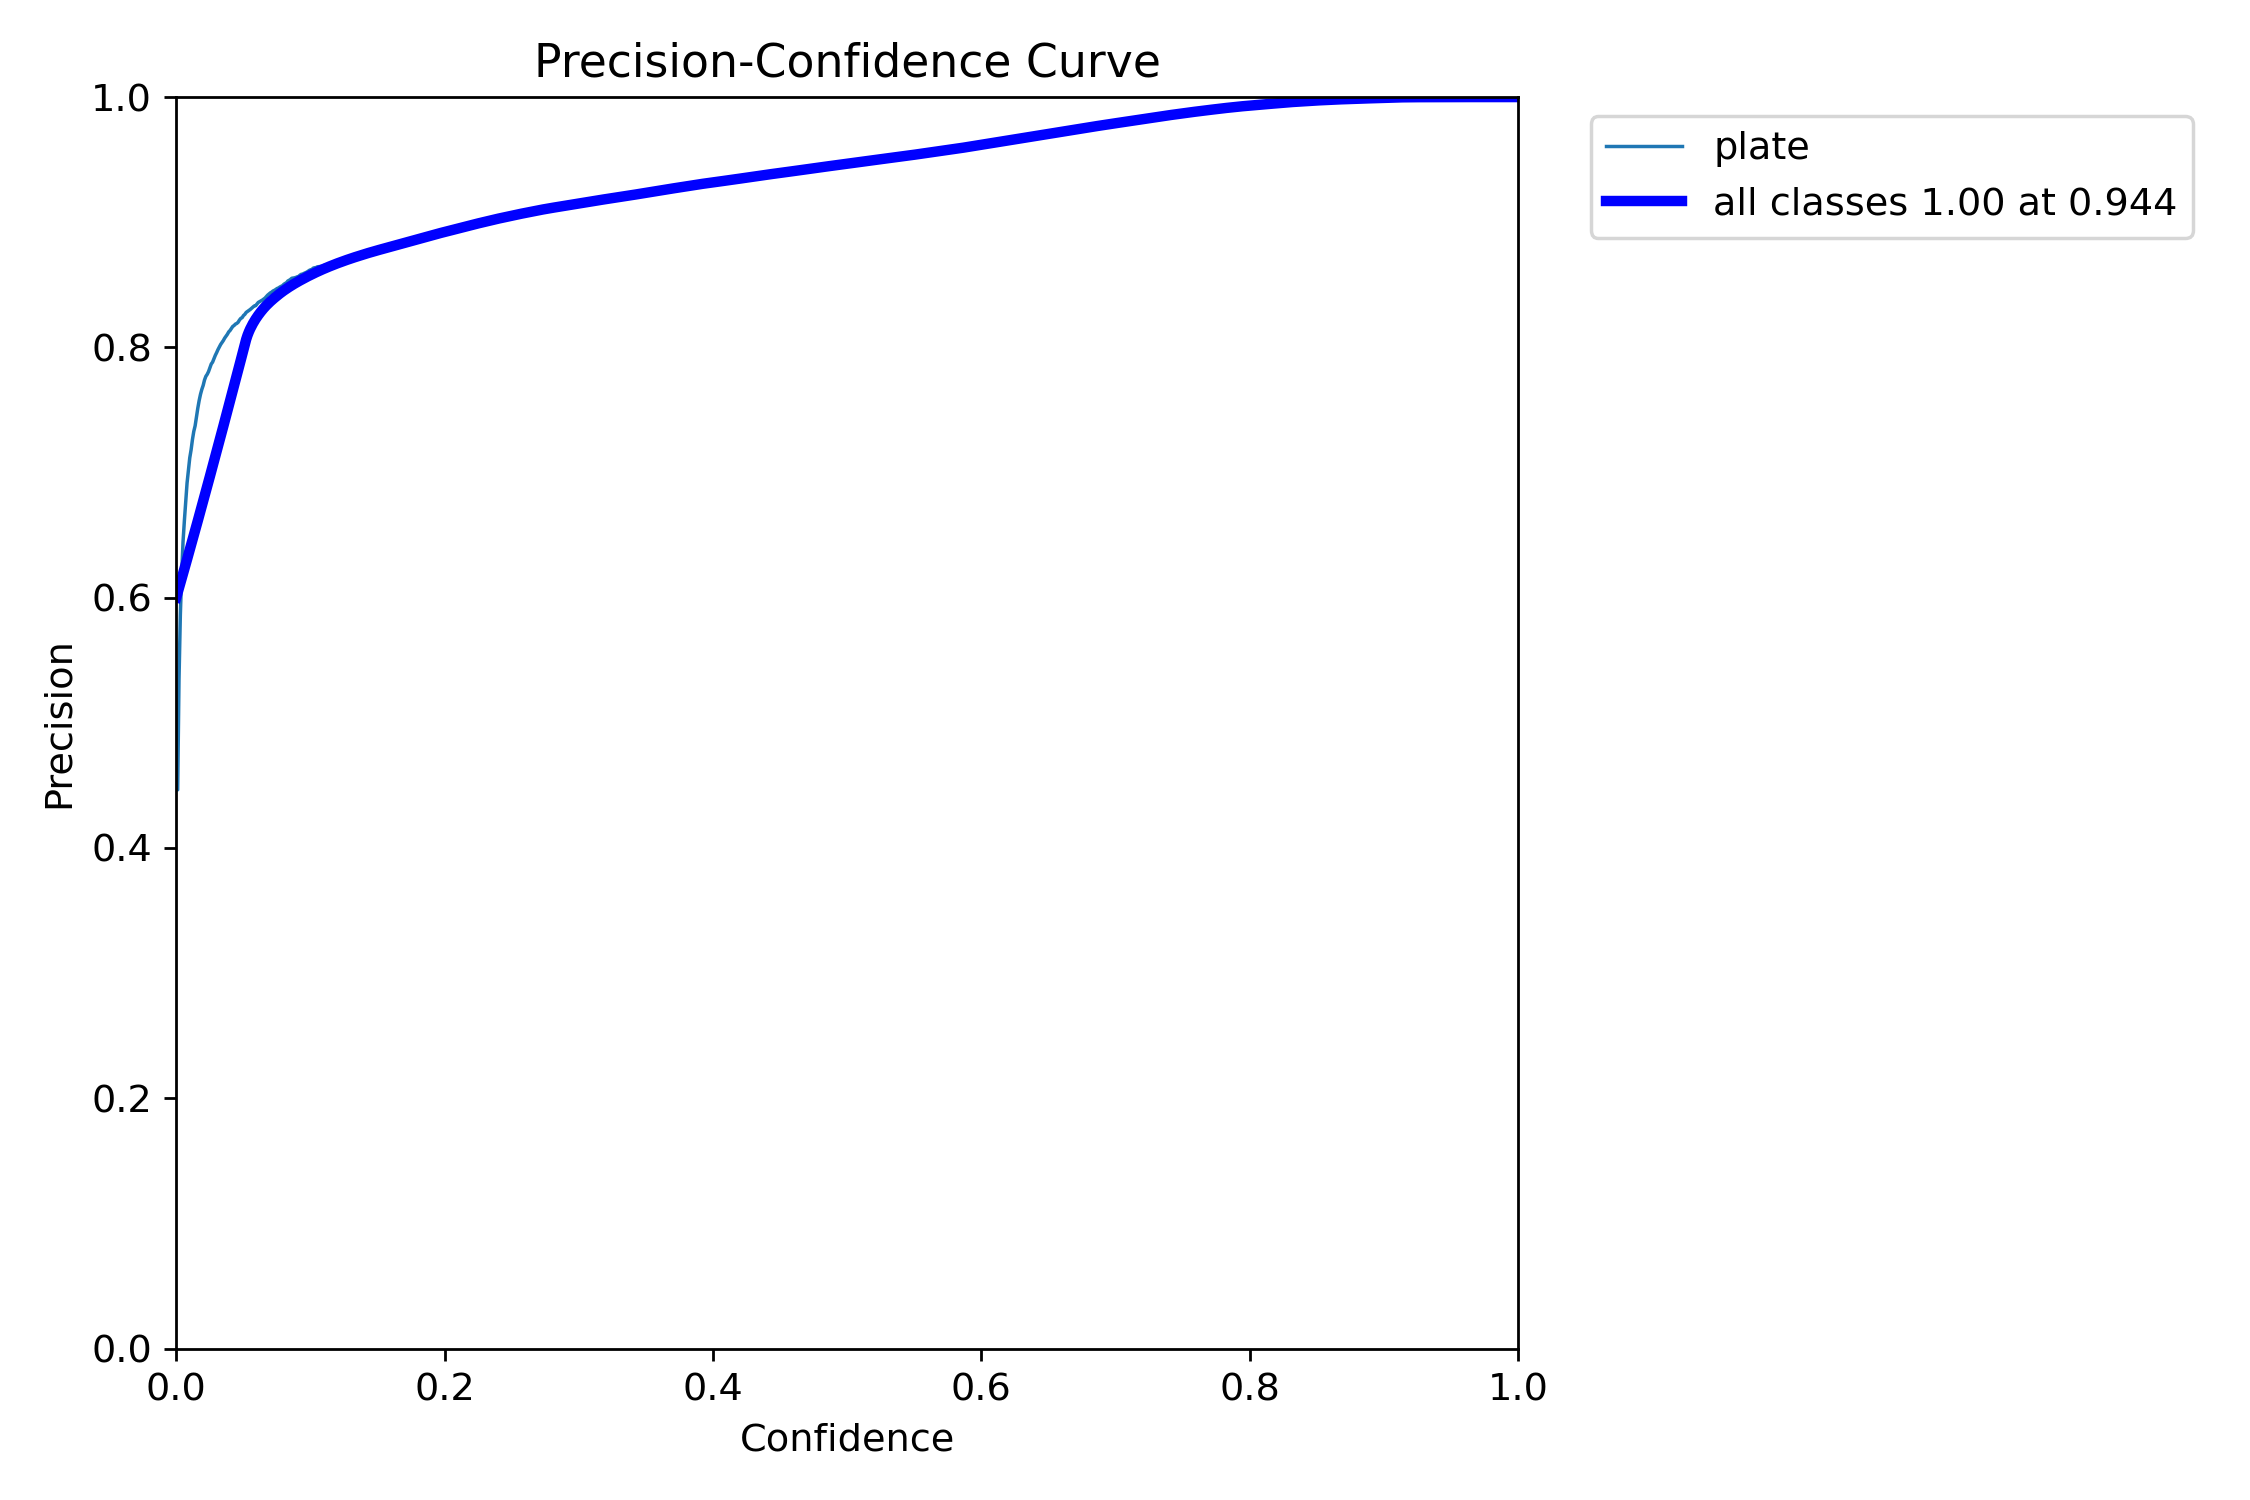

BoxR_curve.png


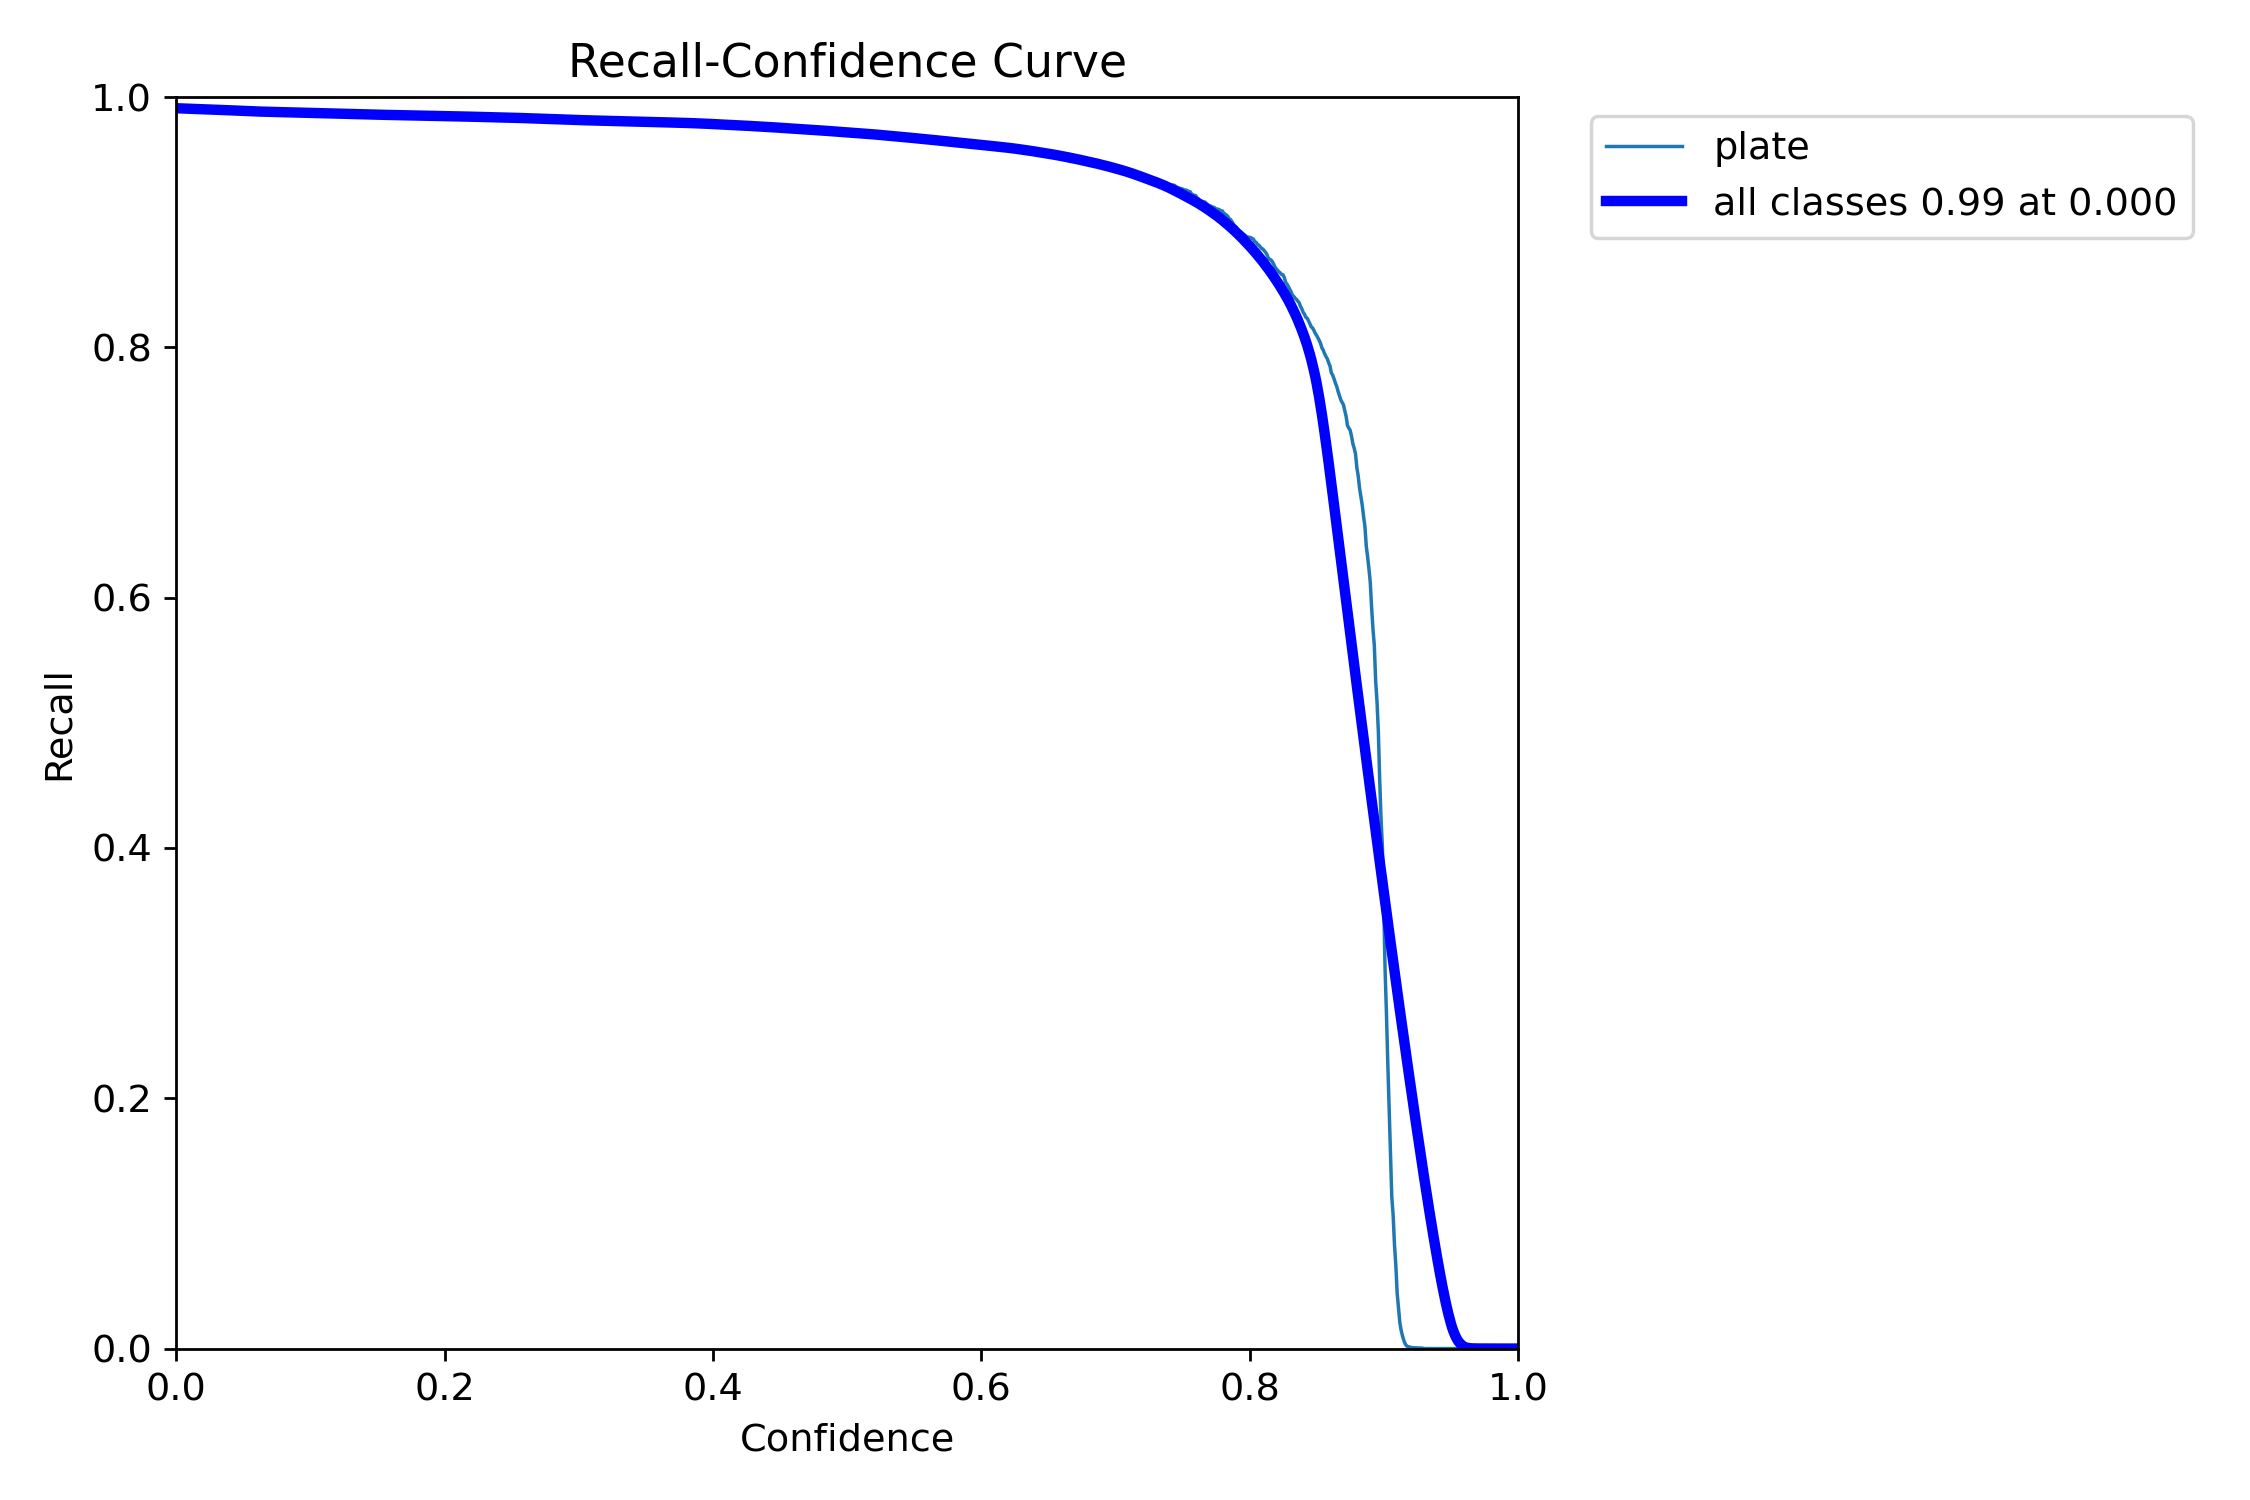

confusion_matrix.png


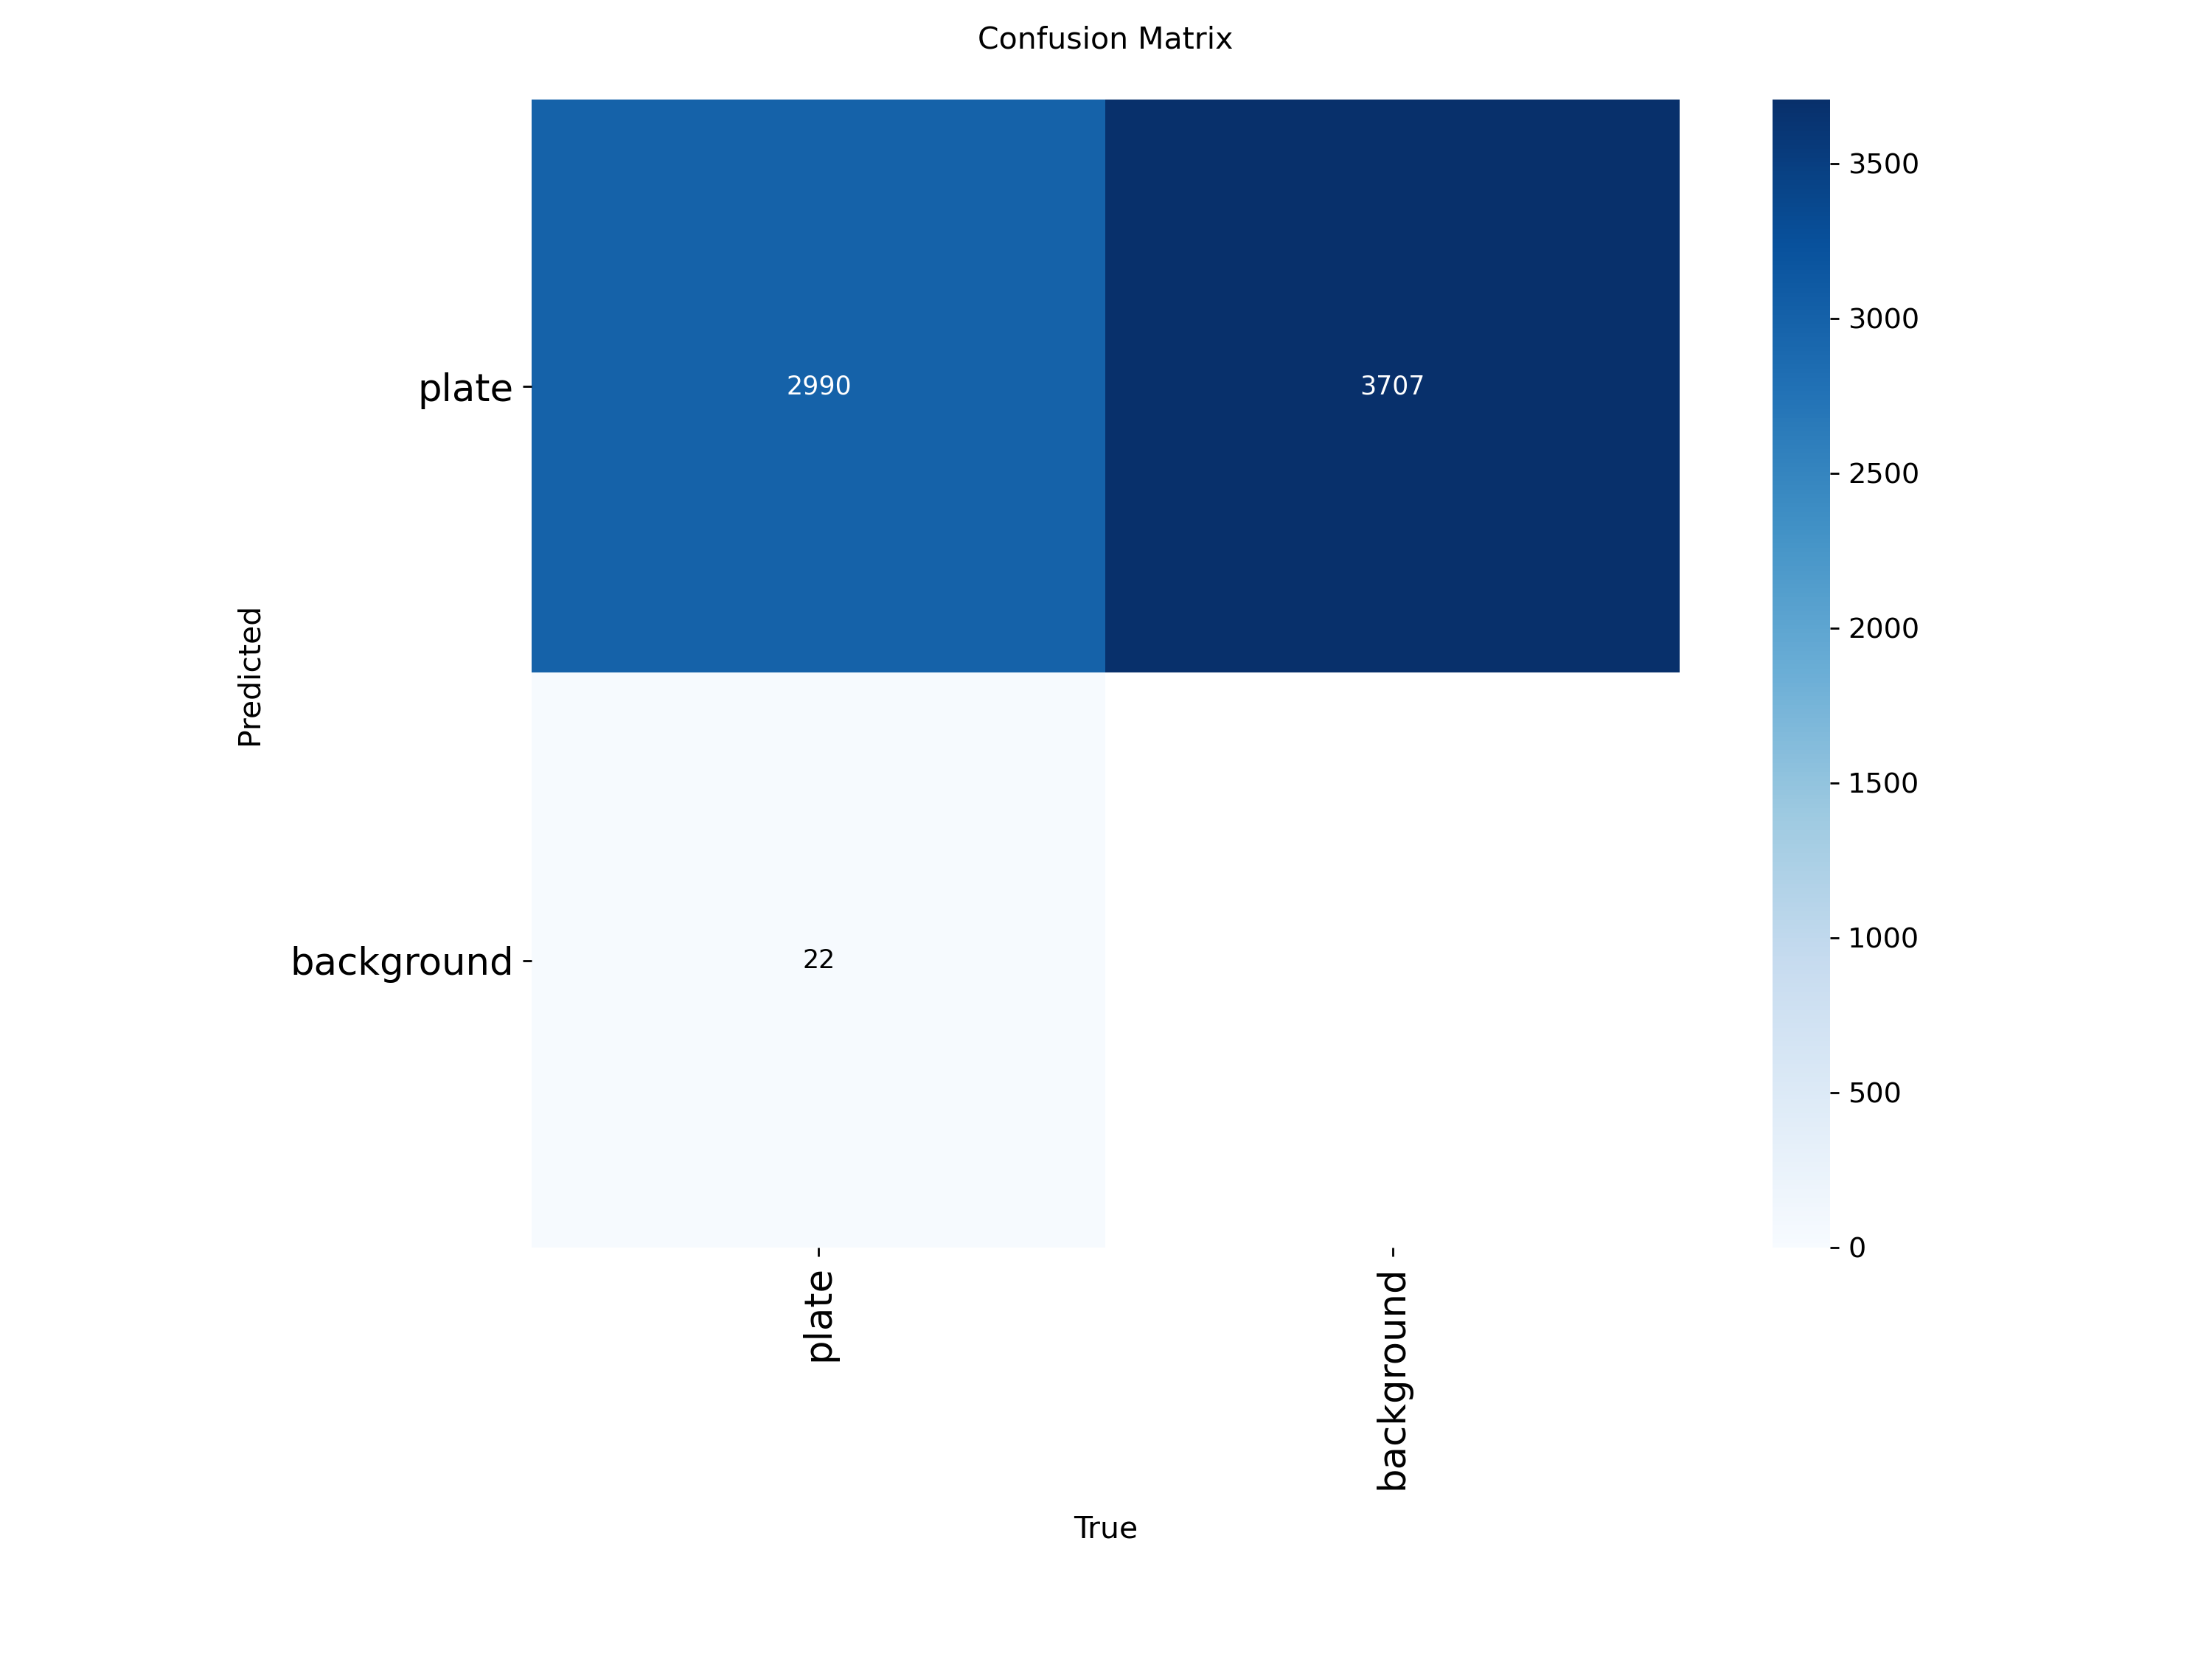

confusion_matrix_normalized.png


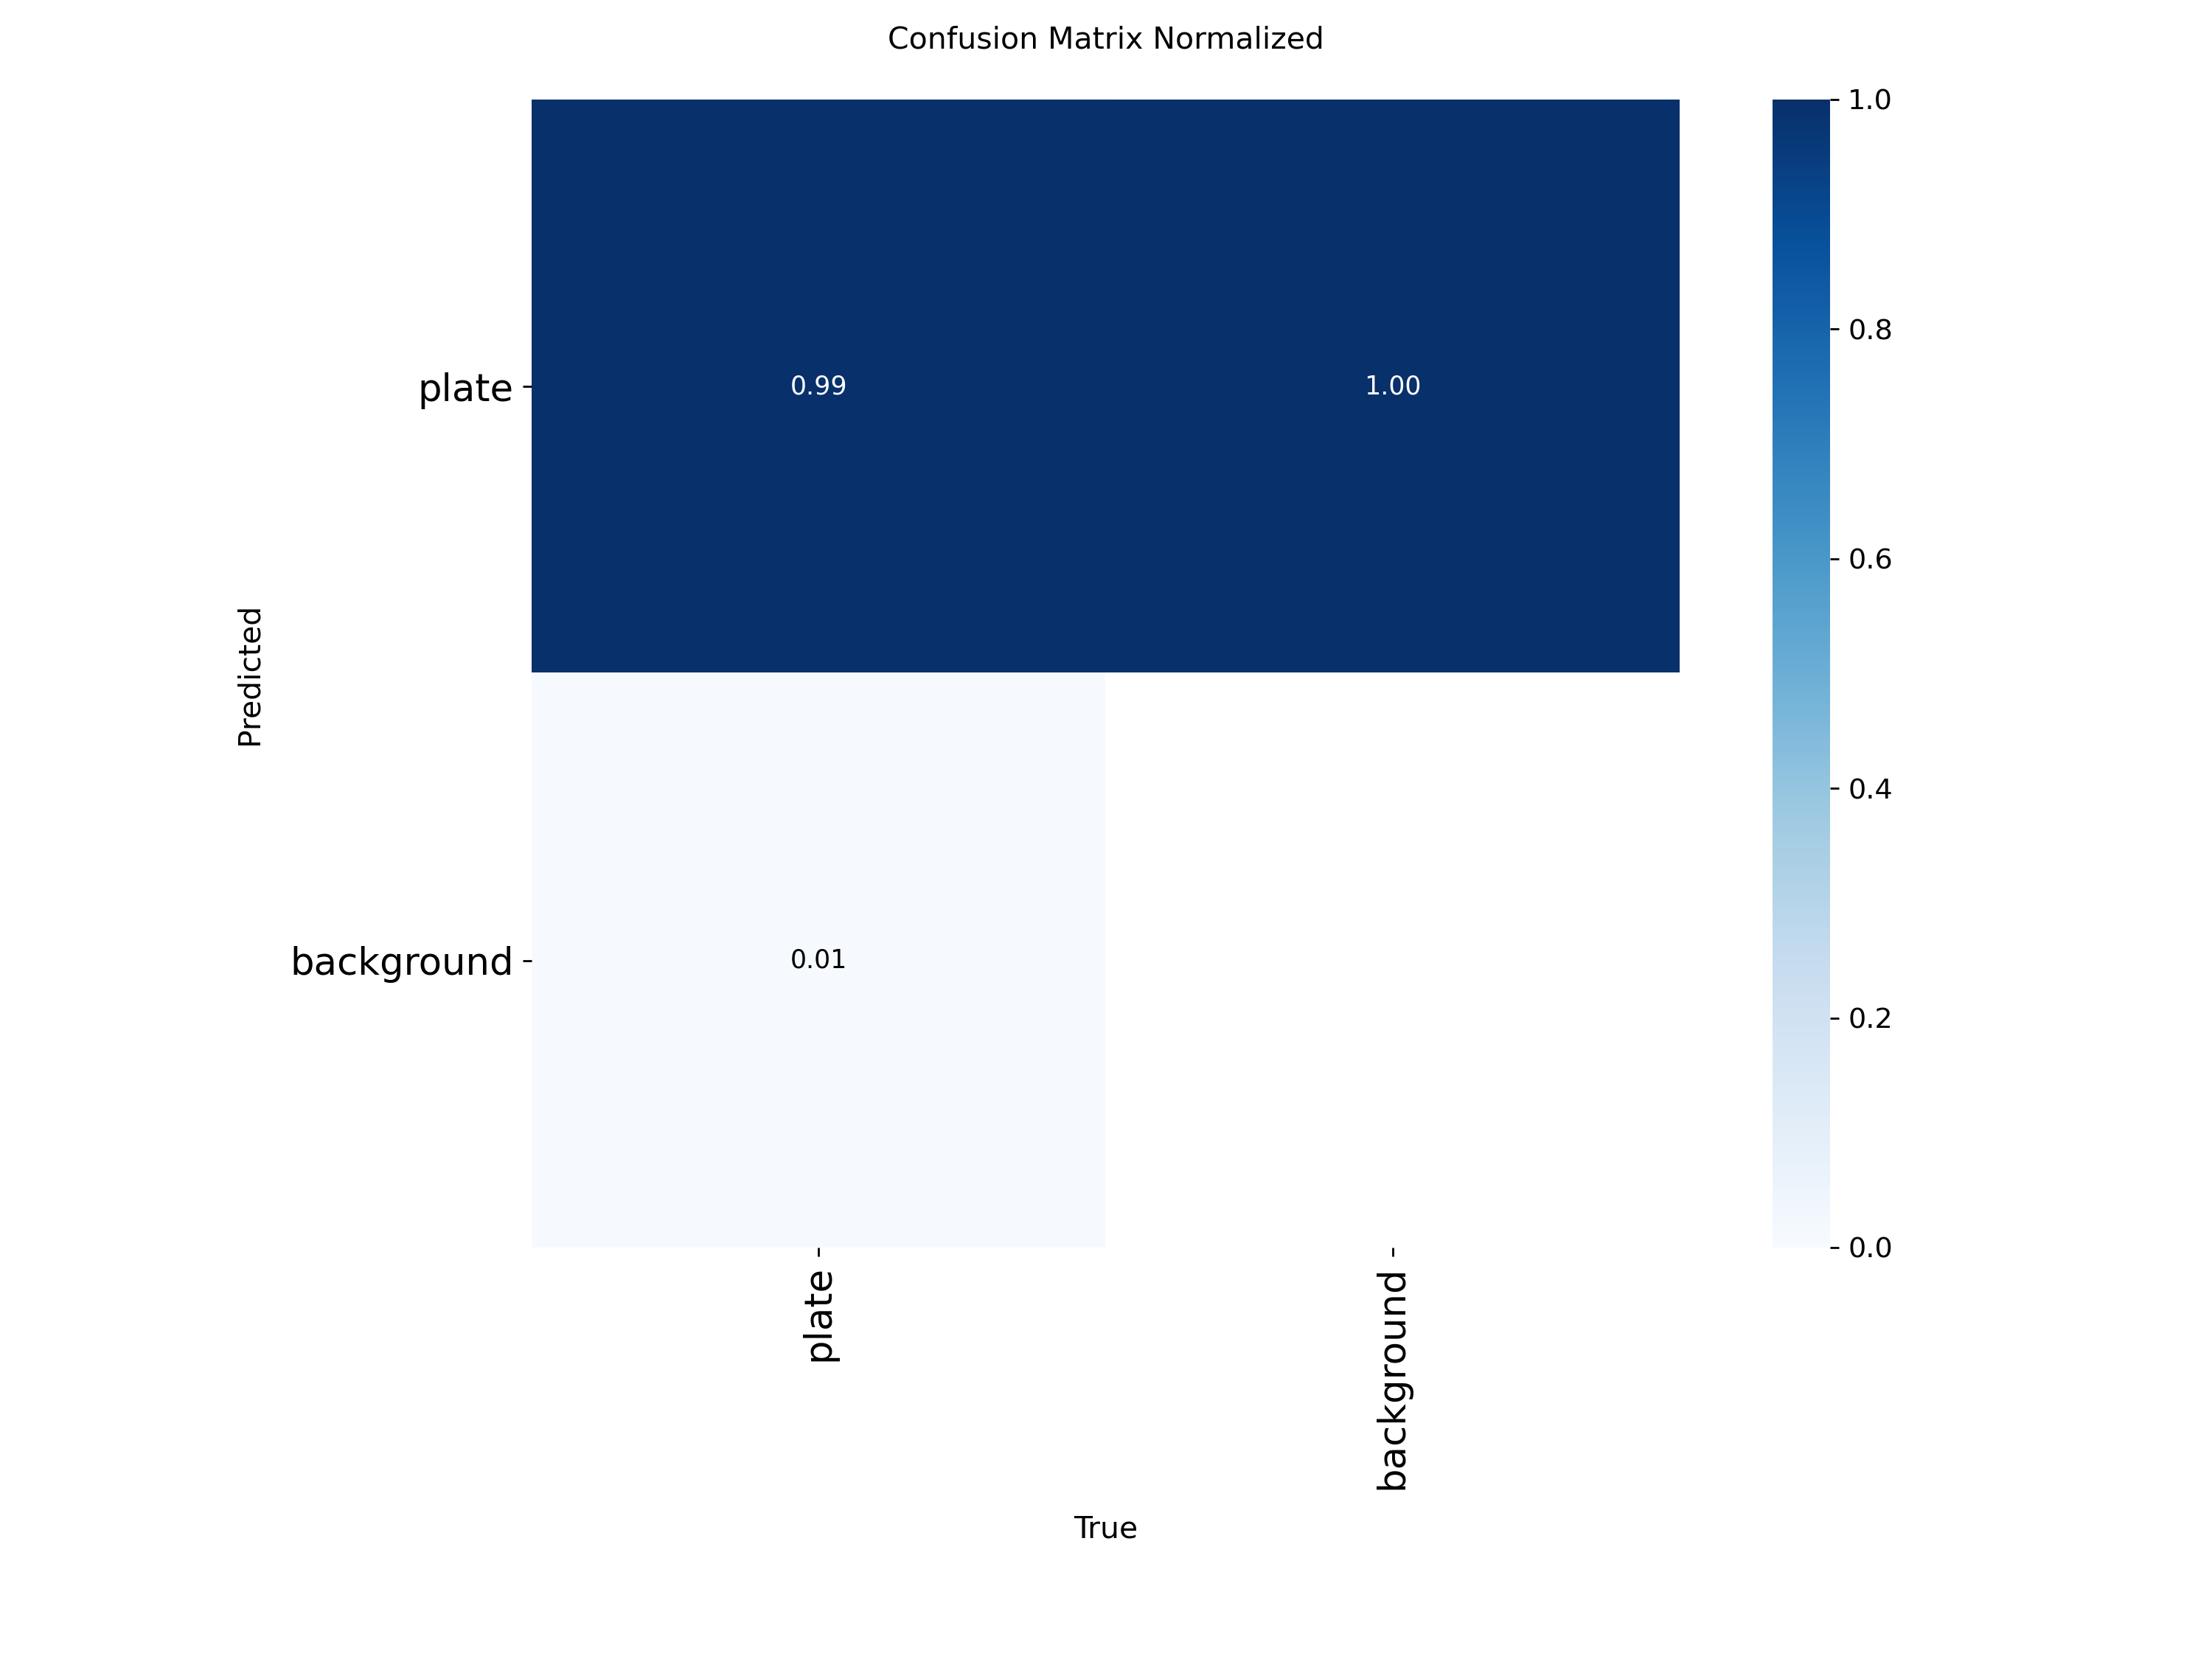

results.png


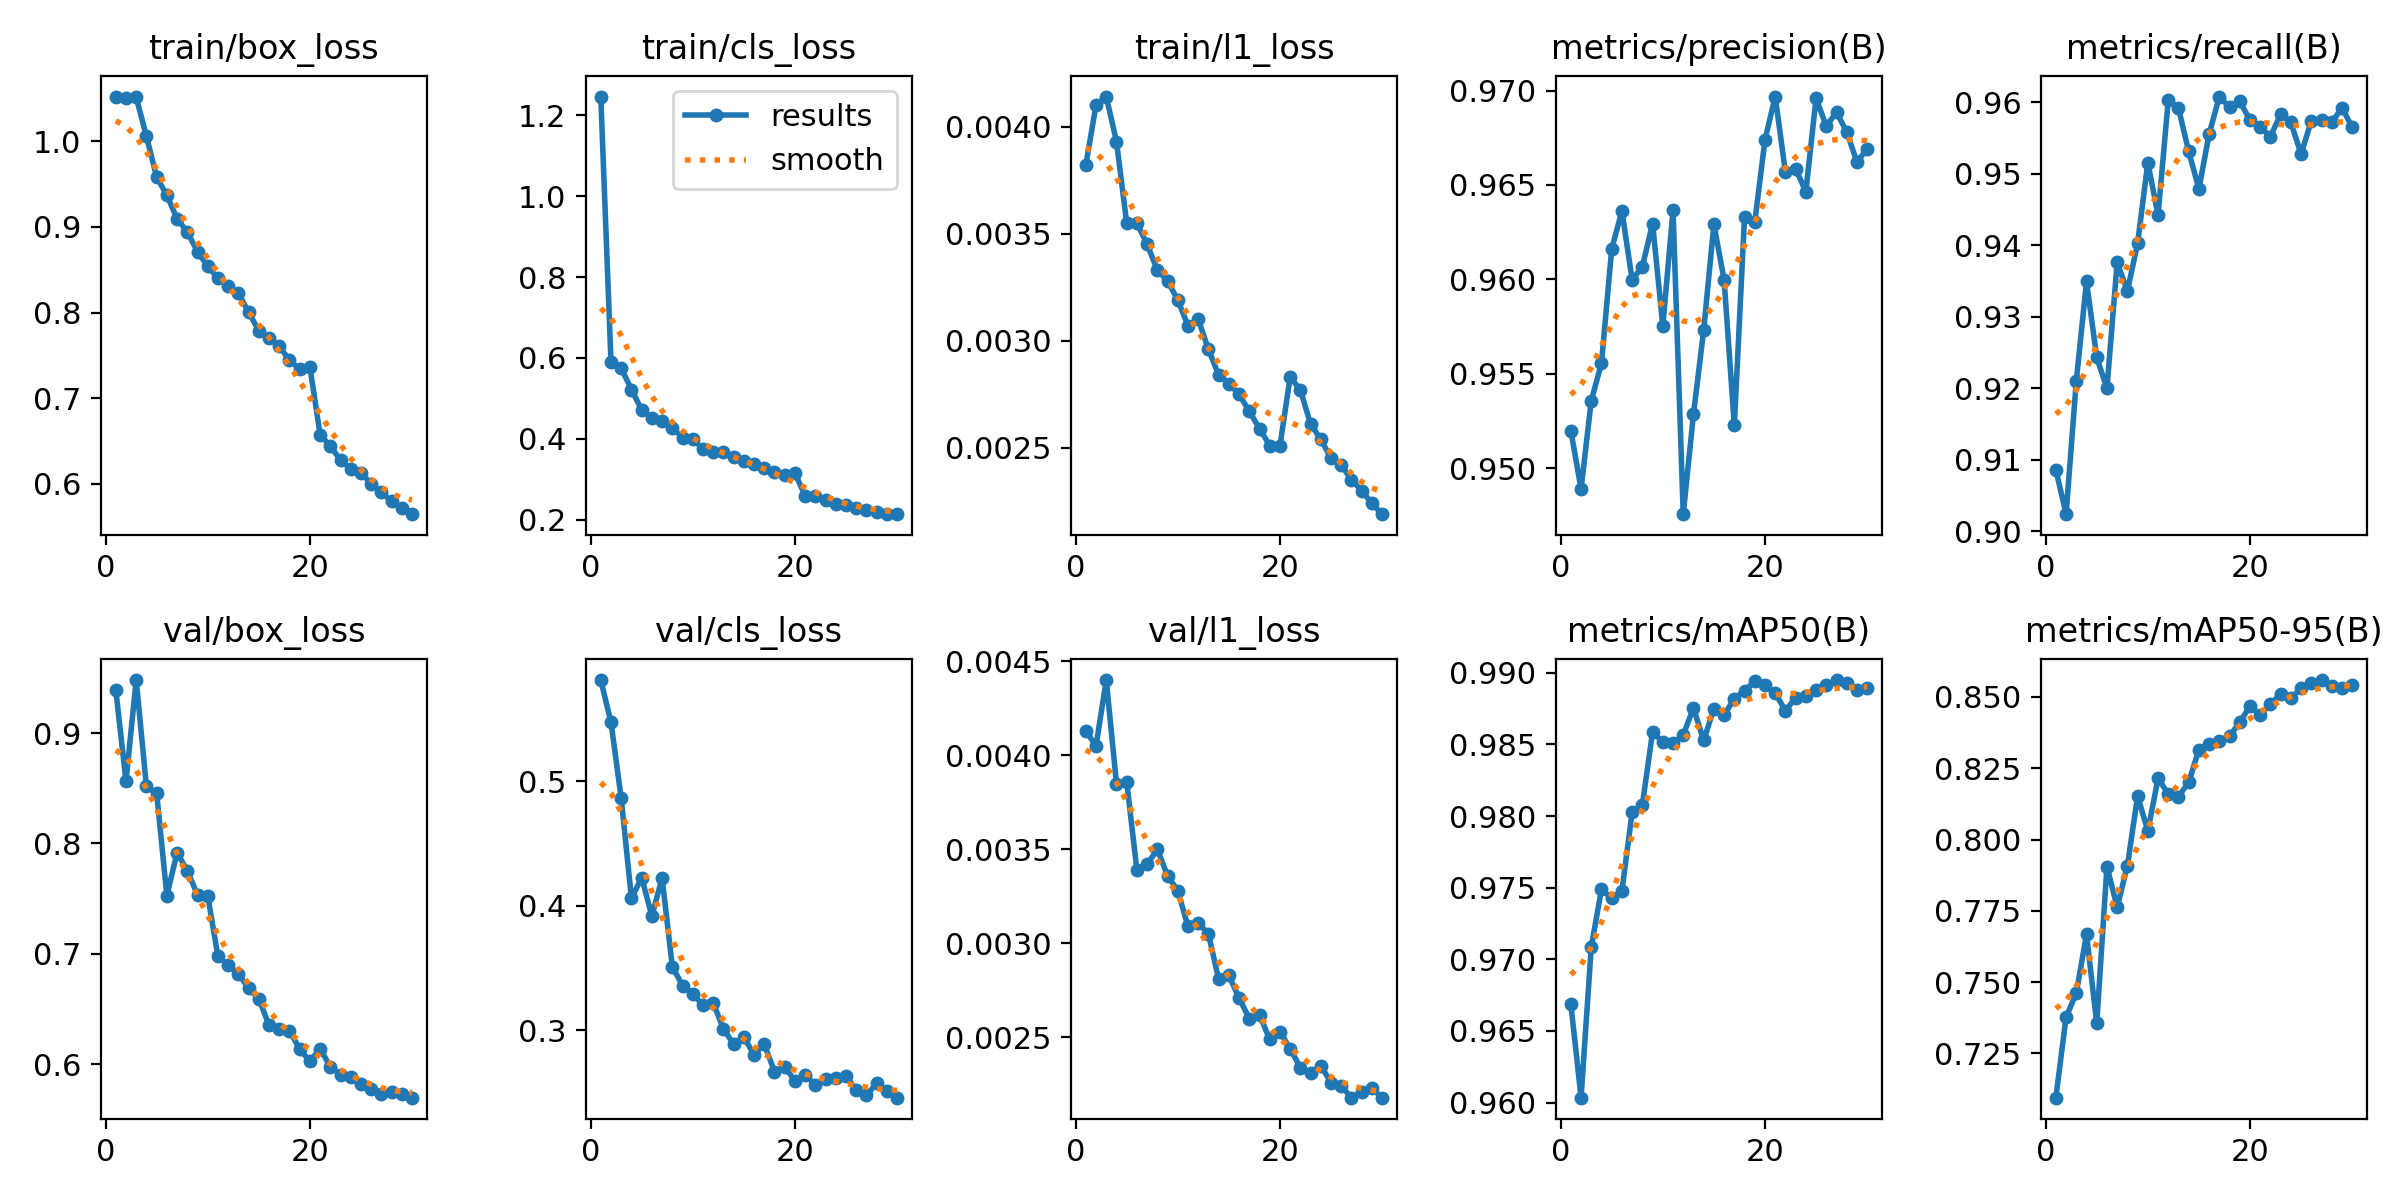

In [21]:
from IPython.display import display, Image
from pathlib import Path

for plot_path in sorted(results_dir.glob("*.png")):
    print(plot_path.name)
    display(Image(filename=str(plot_path)))

In [24]:
!pip install -q easyocr opencv-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 89.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 31.1 MB/s eta 0:00:00


In [38]:
!pip install -q paddleocr paddlepaddle

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 8.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.8/146.8 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 MB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 85.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 759.5/759.5 kB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3

In [31]:
from ultralytics import YOLO
import easyocr
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Load trained plate detector
best_model = YOLO(
    str(Path(results.save_dir) / "weights" / "best.pt")
)

# Initialize OCR
reader = easyocr.Reader(["en"], gpu=True)

print("YOLO26m and EasyOCR loaded successfully!")

YOLO26m and EasyOCR loaded successfully!



OCR candidates:
Text: '3' | Digits: '3' | Confidence: 0.259
Text: '36304' | Digits: '36304' | Confidence: 1.000


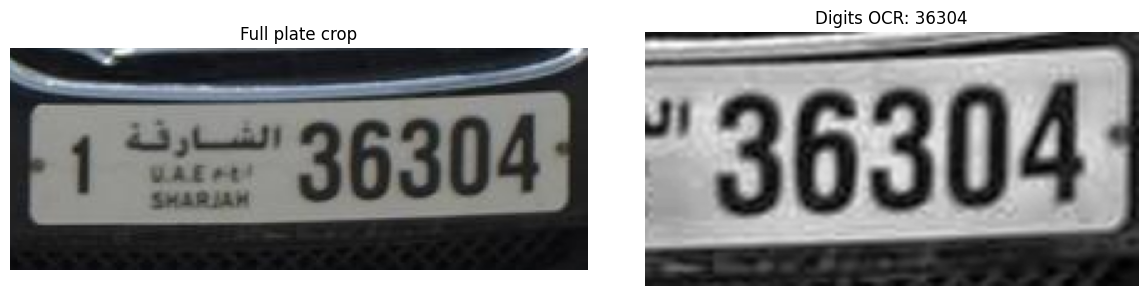

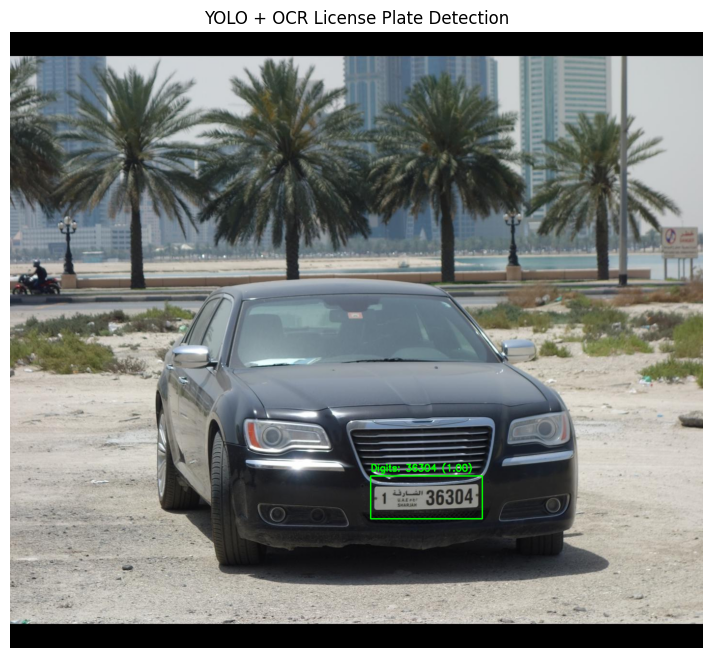


Recognized plate numbers: ['36304']


In [37]:

import cv2
import easyocr
import numpy as np
import matplotlib.pyplot as plt
import re

# ==========================================
# 1. Configuration
# ==========================================
IMAGE_PATH = (
    "/content/car-plate-only/test/images/"
    "1-36304_jpg.rf.d6074bc327abb3fd953c5d69f512b26e.jpg"
)

CONF_THRESHOLD = 0.25

# Initialize OCR
reader = easyocr.Reader(["en"], gpu=True)

# ==========================================
# 2. Run YOLO detection
# ==========================================
image = cv2.imread(IMAGE_PATH)

if image is None:
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

detection_results = best_model.predict(
    source=image,
    imgsz=640,
    conf=CONF_THRESHOLD,
    verbose=False
)

annotated_image = image.copy()
recognized_plates = []

# ==========================================
# 3. Image preprocessing
# ==========================================
def preprocess_digits(crop):
    # Enlarge the crop
    enlarged = cv2.resize(
        crop,
        None,
        fx=3,
        fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    # Convert to grayscale
    gray = cv2.cvtColor(enlarged, cv2.COLOR_BGR2GRAY)

    # Improve local contrast
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    gray = clahe.apply(gray)

    # Reduce small noise
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    return gray

# ==========================================
# 4. Detect, crop, and recognize
# ==========================================
for result in detection_results:
    for box in result.boxes:

        # Get bounding box
        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        h, w = image.shape[:2]

        # Keep coordinates inside the image
        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(w, x2)
        y2 = min(h, y2)

        if x2 <= x1 or y2 <= y1:
            continue

        # Crop the full plate
        plate_crop = image[y1:y2, x1:x2].copy()

        if plate_crop.size == 0:
            continue

        plate_h, plate_w = plate_crop.shape[:2]

        # ----------------------------------
        # 5. Crop the large number section
        # ----------------------------------
        # These ratios are specific to this
        # plate layout; adjust for other plates.
        number_crop = plate_crop[
            int(plate_h * 0.15):int(plate_h * 0.90),
            int(plate_w * 0.42):int(plate_w * 0.98)
        ]

        if number_crop.size == 0:
            continue

        processed_digits = preprocess_digits(number_crop)

        # ----------------------------------
        # 6. OCR: digits only
        # ----------------------------------
        ocr_results = reader.readtext(
            processed_digits,
            detail=1,
            paragraph=False,
            allowlist="0123456789",
            decoder="beamsearch",
            text_threshold=0.5,
            low_text=0.3,
            mag_ratio=1.5
        )

        print("\nOCR candidates:")

        digit_candidates = []

        for bbox, text, confidence in ocr_results:
            digits = re.sub(r"\D", "", text)

            print(
                f"Text: {text!r} | "
                f"Digits: {digits!r} | "
                f"Confidence: {confidence:.3f}"
            )

            if digits and confidence >= 0.30:
                digit_candidates.append((digits, confidence))

        # Select the most confident candidate
        # Do not concatenate separate detections:
        # they may represent separate parts of the plate.
        if digit_candidates:
            number_text, number_confidence = max(
                digit_candidates,
                key=lambda item: item[1]
            )
        else:
            number_text = ""
            number_confidence = 0.0

        recognized_plates.append(number_text)

        # ----------------------------------
        # 7. Draw detection and OCR result
        # ----------------------------------
        cv2.rectangle(
            annotated_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        label = (
            f"Digits: {number_text} ({number_confidence:.2f})"
            if number_text
            else "Digits not recognized"
        )

        cv2.putText(
            annotated_image,
            label,
            (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (0, 255, 0),
            2
        )

        # ----------------------------------
        # 8. Display crops for debugging
        # ----------------------------------
        plt.figure(figsize=(12, 3))

        plt.subplot(1, 2, 1)
        plt.imshow(cv2.cvtColor(plate_crop, cv2.COLOR_BGR2RGB))
        plt.title("Full plate crop")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(processed_digits, cmap="gray")
        plt.title(f"Digits OCR: {number_text}")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

# ==========================================
# 9. Display final result
# ==========================================
plt.figure(figsize=(14, 8))
plt.imshow(
    cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
)
plt.title("YOLO + OCR License Plate Detection")
plt.axis("off")
plt.show()

print("\nRecognized plate numbers:", recognized_plates)
